In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import itertools
import time
import torch
import pylab as plt
# %matplotlib inline
# %matplotlib notebook
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

import memory as mem   
from feedforward import Feedforward

## Helper Functions

In [2]:
def running_mean(x, N):
    cumsum = np.cumsum(np.insert(x, 0, 0)) 
    return (cumsum[N:] - cumsum[:-N]) / float(N)

In [3]:
class DiscreteActionWrapper(gym.ActionWrapper):
    def __init__(self, env: gym.Env, bins = 5):
        """A wrapper for converting a 1D continuous actions into discrete ones.
        Args:
            env: The environment to apply the wrapper
            bins: number of discrete actions
        """
        assert isinstance(env.action_space, spaces.Box)
        super().__init__(env)
        self.bins = bins
        self.orig_action_space = env.action_space
        self.action_space = spaces.Discrete(self.bins)

    def action(self, action):
        """ discrete actions from low to high in 'bins'
        Args:
            action: The discrete action
        Returns:
            continuous action
        """
        return self.orig_action_space.low + action/(self.bins-1.0)*(self.orig_action_space.high-self.orig_action_space.low)  

# DQN

Complete the implemenation of DQN with a main Q-network and a target Q-network

In [4]:
""" Q Network, input: observations, output: q-values for all actions """
class QFunction(Feedforward):
    def __init__(self, observation_dim, action_dim, 
                 hidden_sizes=[100,100], learning_rate = 0.0002):
        super().__init__(input_size=observation_dim, 
                         hidden_sizes=hidden_sizes, 
                         output_size=action_dim)
        self.optimizer=torch.optim.Adam(self.parameters(), 
                                        lr=learning_rate, 
                                        eps=0.000001)
        # The L1 loss is often easier for choosing learning rates etc than for L2 (MSELoss)
        #  Imagine larger q-values (in the hundreds) then an squared error can quickly be 10000!, 
        #  whereas the L1 (absolute) error is simply in the order of 100. 
        self.loss = torch.nn.SmoothL1Loss()
        
    def fit(self, observations, actions, targets):
        # TODO: complete this
        self.optimizer.zero_grad()

        observations_tensor = torch.from_numpy(observations)
        actions_tensor = torch.from_numpy(actions)
        targets_tensor = torch.from_numpy(targets)

        q_values = self.forward(observations_tensor)
        predictions = torch.gather(q_values, dim=1, index=actions_tensor)
        loss = self.loss(predictions, targets_tensor)

        loss.backward()
        self.optimizer.step()

        return loss.item()
    
    def Q_value(self, observations, actions):
        # compute the Q value for the give actions
        # Hint: use the torch.gather function select the right outputs 
        # Complete this
        predictions = self.predict(observations)
        predictions_tensor = torch.from_numpy(predictions)
        return torch.gather(predictions_tensor, dim=1, index=actions)
    
    def maxQ(self, observations):
        # compute the maximal Q-value
        # Complete this
        return np.max(self.predict(observations), axis=1, keepdims=True)
    
    def greedyAction(self, observations):
        # this computes the greedy action
        return np.argmax(self.predict(observations), axis=-1)

In [5]:
class DQNAgent(object):
    """
    Agent implementing Q-learning with NN function approximation.    
    """
    def __init__(self, observation_space, action_space, **userconfig):
        
        if not isinstance(observation_space, spaces.box.Box):
            raise UnsupportedSpace('Observation space {} incompatible ' \
                                   'with {}. (Require: Box)'.format(observation_space, self))
        if not isinstance(action_space, spaces.discrete.Discrete):
            raise UnsupportedSpace('Action space {} incompatible with {}.' \
                                   ' (Reqire Discrete.)'.format(action_space, self))
        
        self._observation_space = observation_space
        self._observation_dim = self._observation_space.shape[0]
        self._action_space = action_space
        self._action_n = action_space.n
        self._config = {
            "eps": 0.05,            # Epsilon in epsilon greedy policies                        
            "discount": 0.95,
            "buffer_size": int(1e5),
            "batch_size": 128,
            "learning_rate": 0.0002,
            "target_update_interval": 20
            # add additional parameters here        
        }
        self._config.update(userconfig)        
        self._eps = self._config['eps']
        self.buffer = mem.Memory(max_size=self._config["buffer_size"])
        
        # complete here
        self.train_iter = 0
        self.Q = QFunction(self._observation_dim, self._action_n)
        self.target_network = QFunction(self._observation_dim, self._action_n)
        # For no target network uncomment this line
        # self.target_network = self.Q
            
    def _update_target_net(self):
        q_network_dict = self.Q.state_dict()
        self.target_network.load_state_dict(q_network_dict)

    
    def act(self, observation, eps=None):
        if eps is None:
            eps = self._eps
        # epsilon greedy
        if np.random.random() > eps:
            action = self.Q.greedyAction(observation)
        else: 
            action = self._action_space.sample()        
        return action
    
    
    def store_transition(self, transition):
        self.buffer.add_transition(transition)

            
    def train(self, iter_fit=32):
        losses = []
        # complete this! 
        # Hint: look at last exercise's solution
        # Hint: while developing print the shape of !all! tensors/arrays to make sure 
        #  they have the right shape: (batchsize, X)  
        
        # Hint: for the target network, update its parameters at the beginning of this function 
        # every k  train calls. 
        if self.train_iter % self._config["target_update_interval"] == 0:
            self._update_target_net()
        self.train_iter += 1
        
        for i in range(iter_fit):
            batch = self.buffer.sample(self._config["batch_size"])

            states = np.stack(batch[:, 0])
            actions = batch[:, 1].reshape(-1, 1).astype(np.int64)
            rewards = batch[:, 2].reshape(-1, 1).astype(np.float32)
            term = batch[:, 4].reshape(-1, 1).astype(np.int64)
            new_states = np.stack(batch[:, 3])

            targets = rewards + (1 - term) * self._config["discount"] * self.target_network.maxQ(new_states)
            
            fit_loss = self.Q.fit(states, actions, targets)
            
            losses.append(fit_loss)    
        return losses

## Test in Env

In [6]:
#env_name = 'Pendulum-v1'
env_name = 'CartPole-v1'

env = gym.make(env_name)
if isinstance(env.action_space, spaces.Box):
    env = DiscreteActionWrapper(env,5)

ac_space = env.action_space
o_space = env.observation_space
print(ac_space)
print(o_space)
print(list(zip(env.observation_space.low, env.observation_space.high)))

Discrete(2)
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
[(np.float32(-4.8), np.float32(4.8)), (np.float32(-inf), np.float32(inf)), (np.float32(-0.41887903), np.float32(0.41887903)), (np.float32(-inf), np.float32(inf))]


In [7]:
q_agent = DQNAgent(o_space, ac_space, discount=0.95, eps=0.2)

In [8]:
ob,_info = env.reset()
q_agent.Q.predict(ob)

array([0.13538583, 0.08784512], dtype=float32)

Train the agent!

In [9]:
stats = []
losses = []

In [10]:
max_episodes=600
max_steps=500 
for i in range(max_episodes):
    # print("Starting a new episode")    
    total_reward = 0
    ob, _info = env.reset()
    for t in range(max_steps):
        done = False        
        a = q_agent.act(ob)
        (ob_new, reward, done, trunc, _info) = env.step(a)
        total_reward+= reward
        q_agent.store_transition((ob, a, reward, ob_new, done))            
        ob=ob_new        
        if done: break    
    losses.extend(q_agent.train(32))
    stats.append([i,total_reward,t+1])    
    
    if ((i-1)%20==0):
        print("{}: Done after {} steps. Reward: {}".format(i, t+1, total_reward))

1: Done after 13 steps. Reward: 13.0
21: Done after 26 steps. Reward: 26.0
41: Done after 27 steps. Reward: 27.0
61: Done after 40 steps. Reward: 40.0
81: Done after 28 steps. Reward: 28.0
101: Done after 36 steps. Reward: 36.0
121: Done after 122 steps. Reward: 122.0
141: Done after 121 steps. Reward: 121.0
161: Done after 140 steps. Reward: 140.0
181: Done after 139 steps. Reward: 139.0
201: Done after 144 steps. Reward: 144.0
221: Done after 169 steps. Reward: 169.0
241: Done after 198 steps. Reward: 198.0
261: Done after 160 steps. Reward: 160.0
281: Done after 156 steps. Reward: 156.0
301: Done after 179 steps. Reward: 179.0
321: Done after 188 steps. Reward: 188.0
341: Done after 158 steps. Reward: 158.0
361: Done after 152 steps. Reward: 152.0
381: Done after 166 steps. Reward: 166.0
401: Done after 170 steps. Reward: 170.0
421: Done after 182 steps. Reward: 182.0
441: Done after 151 steps. Reward: 151.0
461: Done after 141 steps. Reward: 141.0
481: Done after 179 steps. Reward:

Plot the training reward over time. Use the running_mean(array, window_size) to plot a smooth version 

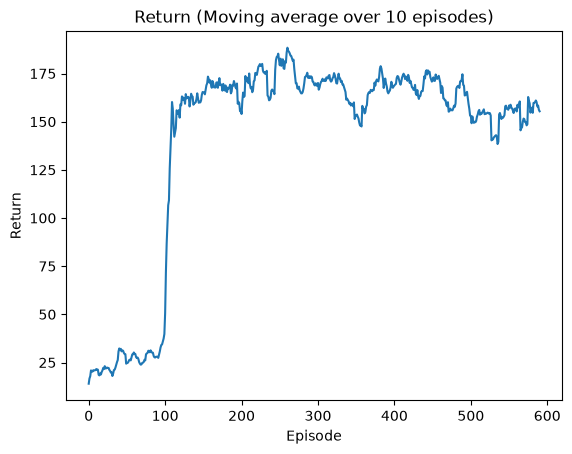

In [11]:
stats_np = np.asarray(stats)
N = 10

mean_rewards = running_mean(stats_np[:, 1], N)

plt.plot(mean_rewards)
plt.title(f"Return (Moving average over {N} episodes)")
plt.xlabel("Episode")
plt.ylabel("Return")
#plt.savefig(f"plots/pendulum/return_train_update_every_20_calls.pdf")
plt.show()

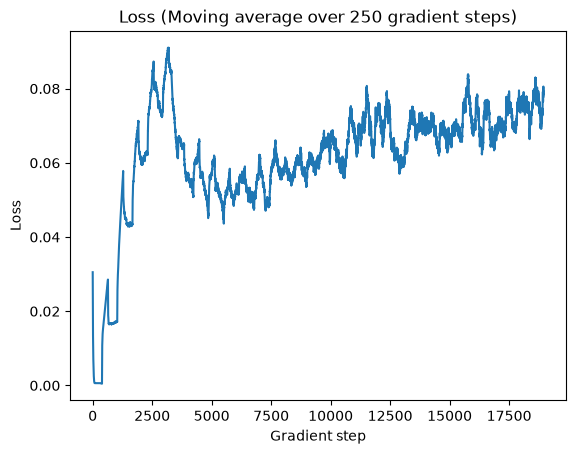

In [12]:
losses_np = np.asarray(losses)
N = 250

mean_losses = running_mean(losses_np, N)

plt.plot(mean_losses)
plt.title(f"Loss (Moving average over {N} gradient steps)")
plt.xlabel("Gradient step")
plt.ylabel("Loss")
#plt.savefig(f"plots/pendulum/loss_train_update_every_20_calls.pdf")
plt.show()

In [13]:
q_agent.buffer.size

83804

## Evaluate (without exploration)

Please look at the behavior for a small number of episodes

In [14]:
env_eval = gym.make(env_name, render_mode="human")
if isinstance(env.action_space, spaces.Box):
    env_eval = DiscreteActionWrapper(env_eval,5)

In [15]:
test_stats = []
episodes=50
env_ = env    # without rendering
#env_ = env_eval # with rendering

for i in range(episodes):
    total_reward = 0
    ob, _info = env_.reset()
    for t in range(max_steps):
        done = False        
        a = q_agent.act(ob, eps=0.0)
        (ob_new, reward, done, trunc, _info) = env_.step(a)
        total_reward+= reward
        ob=ob_new        
        if done: break    
    test_stats.append([i,total_reward,t+1])

test_stats = np.array(test_stats)

Evaluate mean and standard deviation of performance 

(for the Pendulum: an average return around -30 or better should be achieved)

(for the CartPendulum it is possible to get 200)

In [16]:
print(f"Return mean: {np.mean(test_stats[:, 1])}")
print(f"Return std: {np.std(test_stats[:, 1])}")

Return mean: 156.92
Return std: 6.147649957504087


# Visualize

Visualization of the value function.

In [17]:
def plot_value_function(q_network):
    plt.rcParams.update({'font.size': 12})
    xxs =np.linspace(-np.pi/2,np.pi/2)
    yys =np.linspace(-3,3)
    XX,YY=np.meshgrid(xxs,yys)
    dots=np.asarray([np.cos(XX.ravel()),np.sin(XX.ravel()),YY.ravel()]).T
    print(dots.shape)
    # values = np.asarray(test_func(dots)).reshape(XX.shape)
    values =q_network.maxQ(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10,8])
    ax = fig.add_subplot(projection='3d')
    surf = ax.plot_surface(XX, YY, values, cmap=cm.coolwarm,
                           linewidth=0, antialiased=False)
    ax.view_init(elev=30, azim=45, roll=0)
    ax.set_xlabel('angle')
    ax.set_ylabel('angle velocity')
    ax.set_zlabel('value')
    # plt.colorbar(cmap=cm.coolwarm)
    return fig

## Pendulum Env

Observation space:

0 angle

1 angular velocity

(2500, 3)


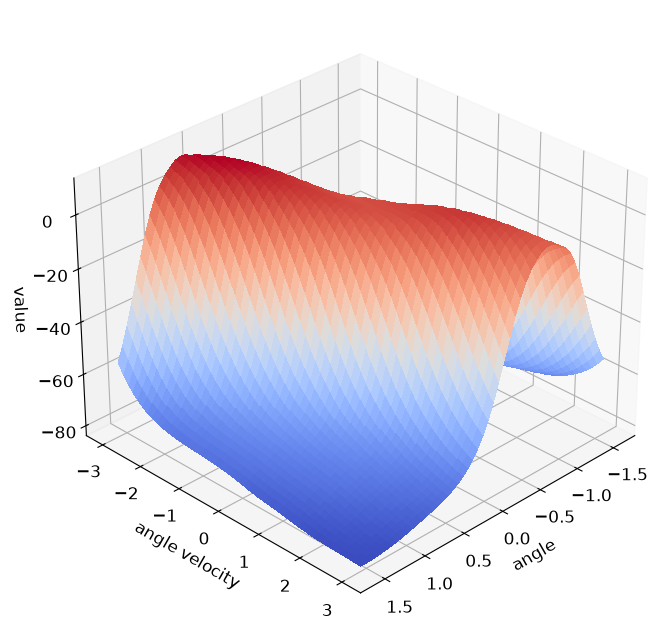

In [ ]:
fig = plot_value_function(q_agent.Q)
#fig.savefig(f"plots/pendulum/value_function_update_every_20_calls.pdf", bbox_inches="tight")

Do that for the pendulum function. Does it look like you expect

Yes, it looks like the one we obtained in the last exercise.

## Cartpole Env

Observation space:
 
0       Cart Position             -4.8                    4.8

1       Cart Velocity             -Inf                    Inf

2       Pole Angle                -0.418 rad (-24 deg)    0.418 rad (24 deg)

3       Pole Angular Velocity     -Inf                    Inf

Try to adapt the plotting function that it also works in higher input spaces where all other inputs are 0

In [16]:
def plot_Q_function_generic(q_function, input_dims, plot_dim1, plot_dim2,
                            label_dim1, label_dim2, ranges=None, n=50):
    """3D surface of max_a Q(s,a) over two input dims; all other inputs are set to 0."""
    if ranges is None:
        # CartPole: cart pos, cart vel, pole angle, pole angular velocity
        ranges = {0: (-2.4, 2.4), 1: (-3, 3), 2: (-0.21, 0.21), 3: (-3, 3)}
    plt.rcParams.update({'font.size': 12})
    xxs = np.linspace(*ranges[plot_dim1], n)
    yys = np.linspace(*ranges[plot_dim2], n)
    XX, YY = np.meshgrid(xxs, yys)
    dots = np.zeros((XX.size, input_dims))
    dots[:, plot_dim1] = XX.ravel()
    dots[:, plot_dim2] = YY.ravel()
    values = q_function.maxQ(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10, 8])
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(XX, YY, values, cmap=cm.coolwarm, linewidth=0, antialiased=False)
    ax.view_init(elev=30, azim=45, roll=0)
    ax.set_xlabel(label_dim1)
    ax.set_ylabel(label_dim2)
    ax.set_zlabel('value')
    return fig

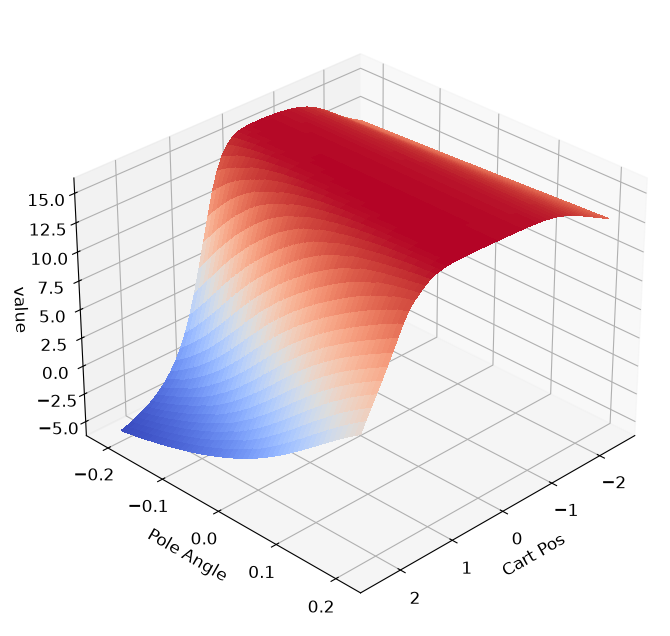

In [17]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=0, plot_dim2=2, 
                       label_dim1="Cart Pos", label_dim2="Pole Angle")
#figQ.savefig("plots/cartpole/value_function_update_every_call_cartpos_poleangle.pdf", bbox_inches="tight")

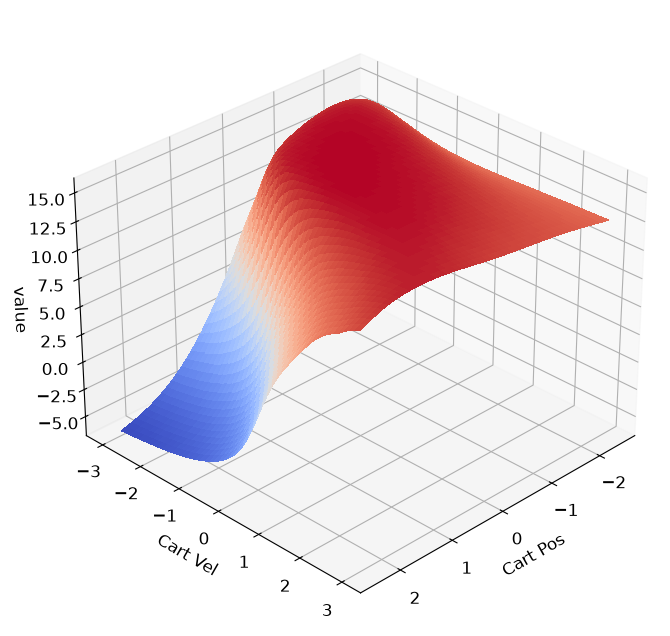

In [18]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=0, plot_dim2=1, 
                       label_dim1="Cart Pos", label_dim2="Cart Vel")
#figQ.savefig("plots/cartpole/value_function_update_every_call_cartpos_cartvel.pdf", bbox_inches="tight")

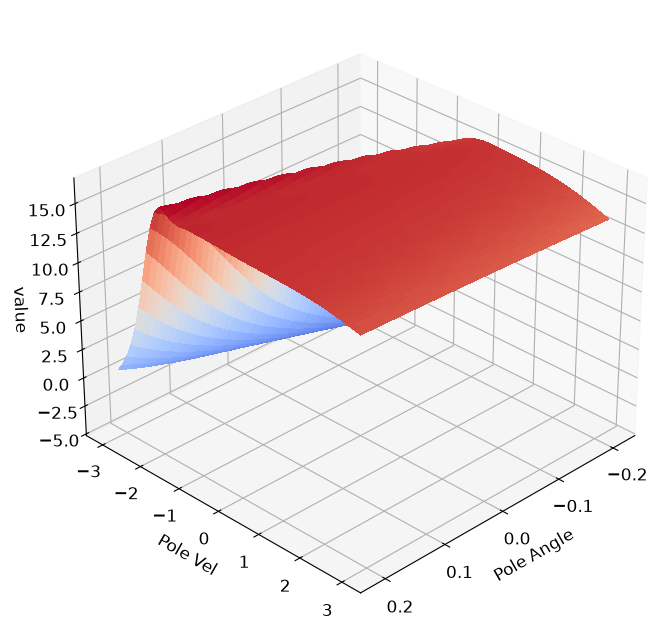

In [19]:
figQ = plot_Q_function_generic(q_agent.Q, input_dims=o_space.shape[0], plot_dim1=2, plot_dim2=3, 
                       label_dim1="Pole Angle", label_dim2="Pole Vel")
#figQ.savefig("plots/cartpole/value_function_update_every_call_poleangle_polevel.pdf", bbox_inches="tight")

In [20]:
# env_name = 'Acrobot-v1'
# env_name = 'MountainCar-v0'
# env_name = 'LunarLander-v2'